# Import and read data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split


In [2]:
from sklearn import datasets
from sklearn.decomposition import PCA

In [3]:
# Load the Iris dataset (sklearn instruction)
iris = datasets.load_iris()

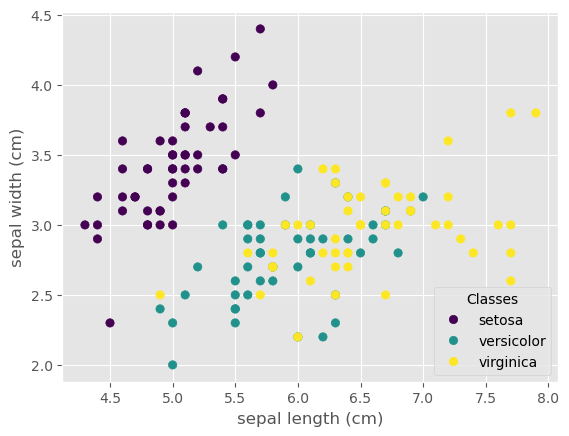

In [4]:
# Scatter plot of the dataset (sklearn instruction)
_, ax = plt.subplots()
scatter = ax.scatter(iris.data[:, 0], iris.data[:, 1], c=iris.target)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
_ = ax.legend(
    scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes"
)
plt.show()

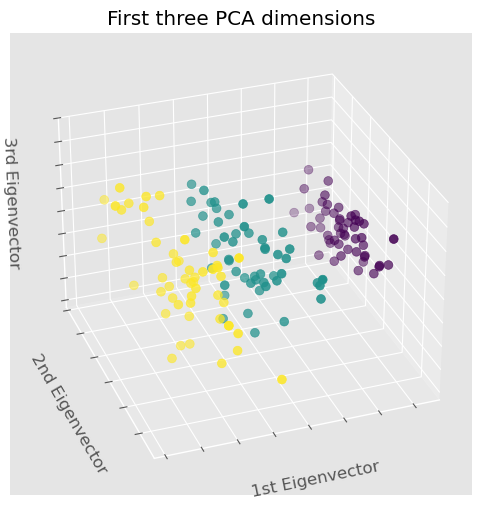

In [5]:
# Scatter plot of the dataset in 3D (sklearn instruction)
import mpl_toolkits.mplot3d  # noqa: F401


fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(iris.data)
ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=iris.target,
    s=40,
)

ax.set_title("First three PCA dimensions")
ax.set_xlabel("1st Eigenvector")
ax.xaxis.set_ticklabels([])
ax.set_ylabel("2nd Eigenvector")
ax.yaxis.set_ticklabels([])
ax.set_zlabel("3rd Eigenvector")
ax.zaxis.set_ticklabels([])

plt.show()

In [6]:
# Turning into a pandas dataframe
iris = datasets.load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Data understanding

In [7]:
df['species'] = iris.target

In [8]:
df.shape

# We have 150 examples and 5 features. 

(150, 5)

In [9]:
df.head(150)

# All the columns have relevant information, none needed to be dropped.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [10]:
df.columns

# The first 4 features are sepal length, sepal width, petal length and petal width, all in cm. The last one is species

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='str')

In [11]:
df.dtypes

# Input type for first 4 columns is float64, for species is int64

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
dtype: object

In [12]:
df.describe()

# The data for the 4 attributes is spread quite evenly round the mean/median (they are not far from each other), and the amount of flowers classified '2' is the same as '0'

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


# Data preparation

In [13]:
# Renaming columns (I don't want space in the names)
df = df.rename(columns={
    'sepal length (cm)': 'sepal_length',
    'sepal width (cm)': 'sepal_width',
    'petal length (cm)': 'petal_length',
    'petal width (cm)': 'petal_width'
})

In [14]:
df.columns

# the names changes as expected

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [15]:
df.isna().sum()

# No missing values, so no rows need to be removed

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [16]:
df.duplicated().sum()
# There is 1 duplicated line


np.int64(1)

In [17]:
df.loc[df.duplicated()]

# Detect the duplicated line: 142

,sepal_length,sepal_width,petal_length,petal_width,species
142,5.8,2.7,5.1,1.9,2


In [18]:
df = df.loc[~df.duplicated()].reset_index(drop = True).copy()

# drop the duplicated line

In [19]:
df.shape

# it has 1 line less now, as expected

(149, 5)

# Feature understanding

Text(0, 0.5, 'Frequency')

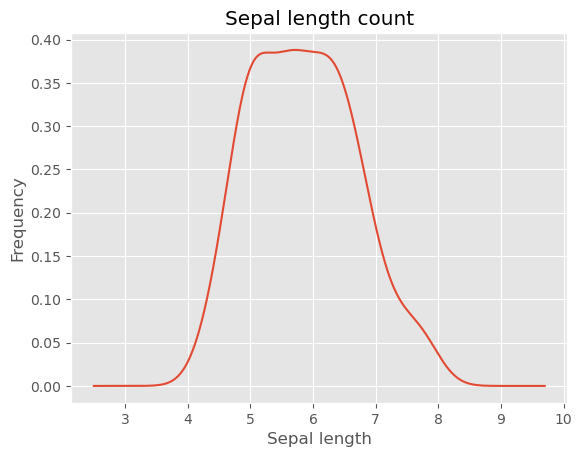

In [20]:
ax = df['sepal_length'].plot(kind = 'kde',
                title = 'Sepal length count')
ax.set_xlabel('Sepal length')
ax.set_ylabel('Frequency')

# even distribution with mean approximately 5.75cm

Text(0, 0.5, 'Frequency')

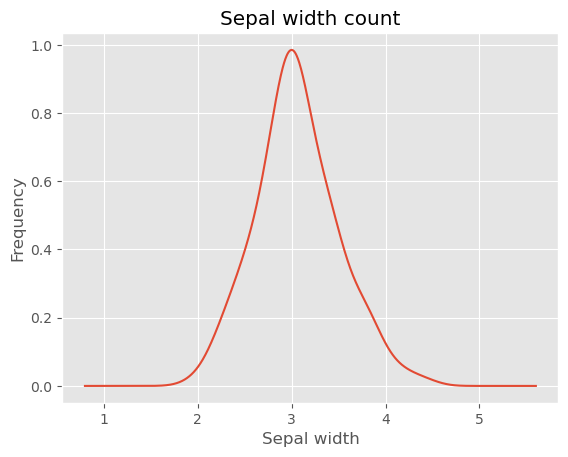

In [21]:
ay = df['sepal_width'].plot(kind = 'kde',
                title = 'Sepal width count')
ay.set_xlabel('Sepal width')
ay.set_ylabel('Frequency')

# even distribution with mean approximately 3cm

Text(0, 0.5, 'Frequency')

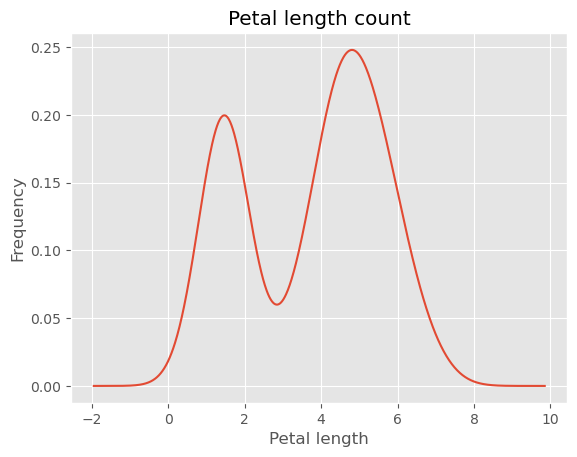

In [22]:
bx = df['petal_length'].plot(kind = 'kde',
                title = 'Petal length count')
bx.set_xlabel('Petal length')
bx.set_ylabel('Frequency')

# quite strange distribution with 2 maximums and 1 dip in between at around

Text(0, 0.5, 'Frequency')

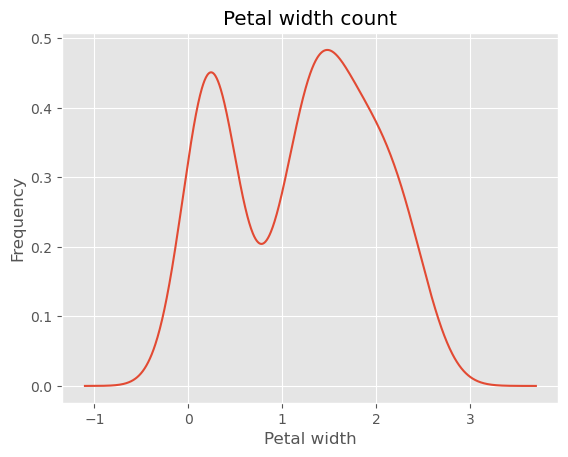

In [23]:
by = df['petal_width'].plot(kind = 'kde',
                title = 'Petal width count')
by.set_xlabel('Petal width')
by.set_ylabel('Frequency')

# quite similar distribution shape to petal length, so the distribution is probably specific to petal or sepal

Text(0, 0.5, 'Counts')

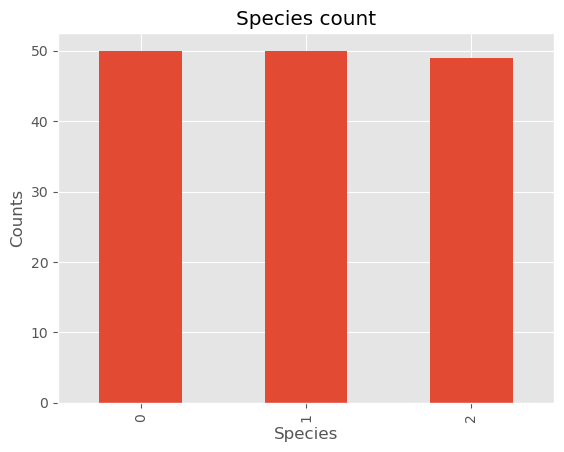

In [24]:
sp = df['species'].value_counts().head(10).plot(kind = 'bar', title = 'Species count')

sp.set_xlabel('Species')
sp.set_ylabel('Counts')

# The amount of each species is very close to each other. I assume at first it was 50-50-50 but then I removed a duplicate so it is 50-50-49

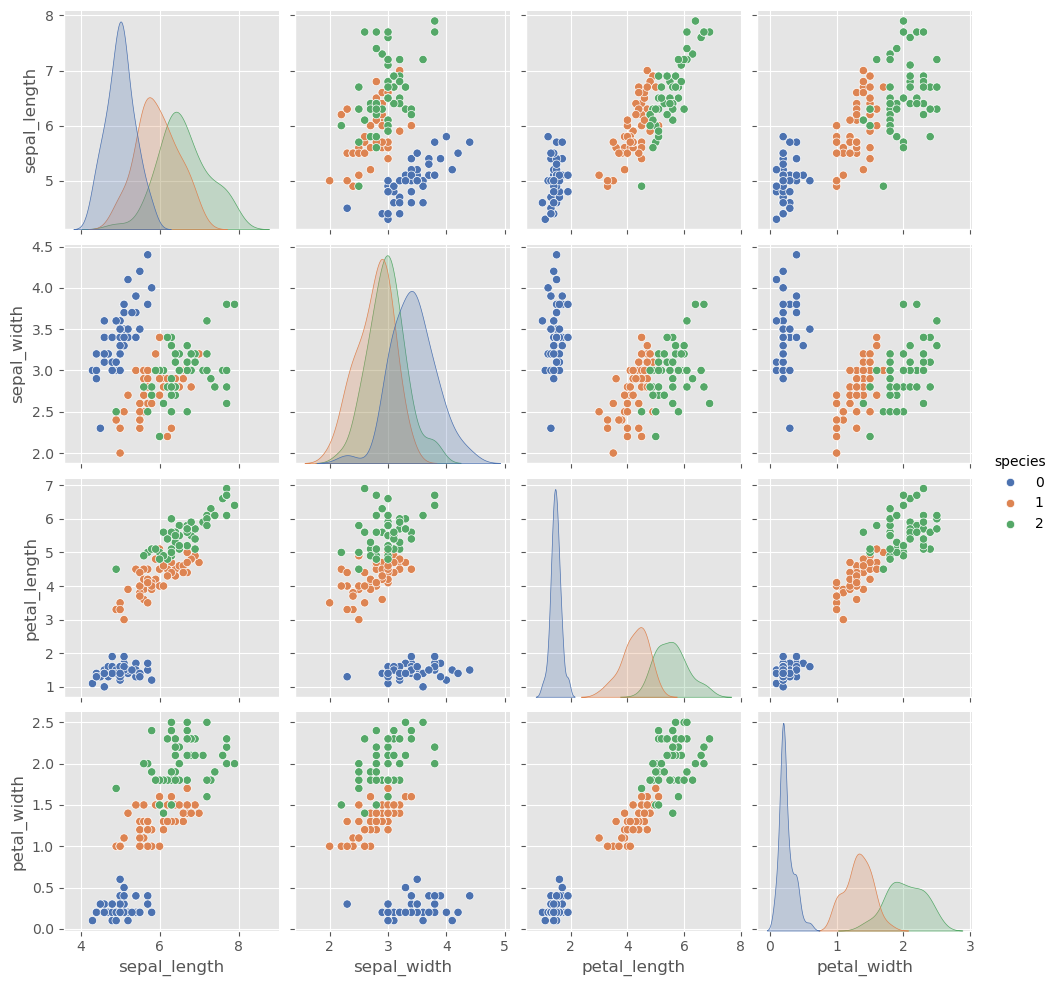

In [25]:
sns.pairplot(df,
             vars = ['sepal_length','sepal_width','petal_length','petal_width'],
             hue = 'species',
             palette='deep')
plt.show()

# We can see the species 0 is quite different from the other two. 1 and 2 have traits closer to each other but there are still some distinction.
# Compare the sepal_width vs sepal_length graph with the one given by sklearn. We can detect the species as follow:
# 0 - setosa, 1 - versicolor, 2 - virginica

# Modelling:

In [26]:
# Create sets for model

X = df.drop(columns='species')
y = df['species']

# Get 60% of the dataset as the training set. Put the remaining 40% in temporary variables: x_ and y_.
X_train, X_, y_train, y_ = train_test_split(X, y, test_size=0.40, random_state=1)

# Split the 40% subset above into two: one half for cross validation and the other for the test set
X_cv, X_test, y_cv, y_test = train_test_split(X_, y_, test_size=0.50, random_state=1)

# Delete temporary variables
del X_, y_

In [ ]:
# Create model
model = Sequential(
    [
        Dense(2, activation = 'relu',   name = "L1"), # 2 lines
        Dense(3, activation = 'linear', name = "L2")  # 3 values
    ]
)

In [37]:
# Train model with training set

model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(0.01),
)

model.fit(
    X_train,y_train,
    epochs=1000
)

#Run until the loss does not drop anymore, about 0.0700

Epoch 1/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.0925 
Epoch 2/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.0703
Epoch 3/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0636
Epoch 4/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.0444
Epoch 5/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0310
Epoch 6/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.0145
Epoch 7/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9937
Epoch 8/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9738
Epoch 9/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.9506
Epoch 10/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9281
Epoch 11/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.9054
Epoch 12/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.8822
Epoch 13/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.8569
Epoch 14/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.8347
Epoch 15/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.8130
Epo

In [38]:
model.export('E:/Projects/iris-flower-classification/saved_model')

# model.save wasn't working for me
#loaded_model = tf.saved_model.load('E:/Projects/iris-flower-classification/saved_model')

INFO:tensorflow:Assets written to: E:/Projects/iris-flower-classification/saved_model\assets


INFO:tensorflow:Assets written to: E:/Projects/iris-flower-classification/saved_model\assets


Saved artifact at 'E:/Projects/iris-flower-classification/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 4), dtype=tf.float32, name='keras_tensor_3')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2222578450256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2222579008720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2222579008144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2222579007952: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [ ]:
# Accuracy check
from sklearn.metrics import accuracy_score
y_pred_probs = model.predict(X_cv)
y_pred = np.argmax(y_pred_probs, axis=1) # get the highest value
accuracy = accuracy_score(y_cv, y_pred)
print(f"CV accuracy: {accuracy:.3f}")

# this model does very well on Iris

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
CV accuracy: 1.000
